Iniziamo caricando i csv elaborato prima e lo verifichiamo


In [1]:
import pandas as pd

df = pd.read_csv("incidenti_2010_2023_regioni.csv", encoding="utf-8")
print(df.dtypes)
print(df.shape)   

REF_AREA                   int64
Comune                       str
TIME_PERIOD                int64
feriti                     int64
incidenti                  int64
morti                      int64
Popolazione residente      int64
densita                  float64
Codice Regione             int64
Codice Provincia/Uts       int64
Sigla automobilistica        str
Superficie (Kmq)         float64
morti_100k               float64
feriti_100k              float64
incidenti_100k           float64
indice_mortalita         float64
incidenti_kmq            float64
Regione                      str
dtype: object
(103432, 18)


Analizzo i dati alivello Nazionale raggruppando tutti i dati

In [2]:
naz = df.groupby("TIME_PERIOD")[["morti", "feriti", "incidenti"]].sum()
naz

,morti,feriti,incidenti
TIME_PERIOD,,,
2010,3961,296183,207286
2011,3713,283925,200330
2012,3595,259335,183250
2013,3226,250661,176643
2014,3244,243675,172170
2015,3273,239620,169593
2016,3124,241778,170852
2017,3234,239606,170088
2018,3169,235673,167576


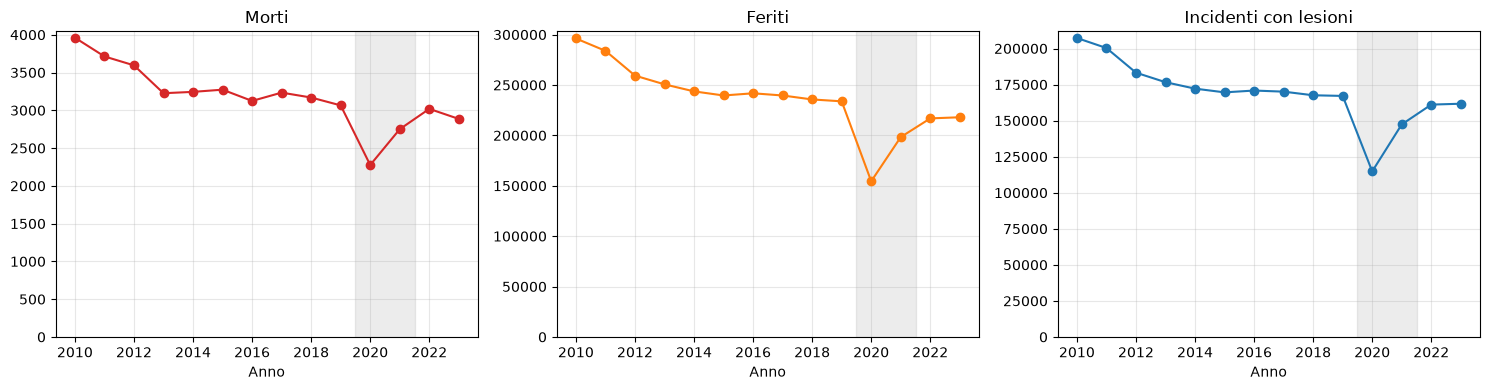

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for a, col, titolo, colore in zip(
    ax,
    ["morti", "feriti", "incidenti"],
    ["Morti", "Feriti", "Incidenti con lesioni"],
    ["tab:red", "tab:orange", "tab:blue"],
):
    a.plot(naz.index, naz[col], marker="o", color=colore)
    a.axvspan(2019.5, 2021.5, alpha=0.15, color="gray")   
    a.set_title(titolo)
    a.set_xlabel("Anno")
    a.set_ylim(bottom=0)
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Li sovrappongo per capire se tra di loro vi sono scostamenti significativi

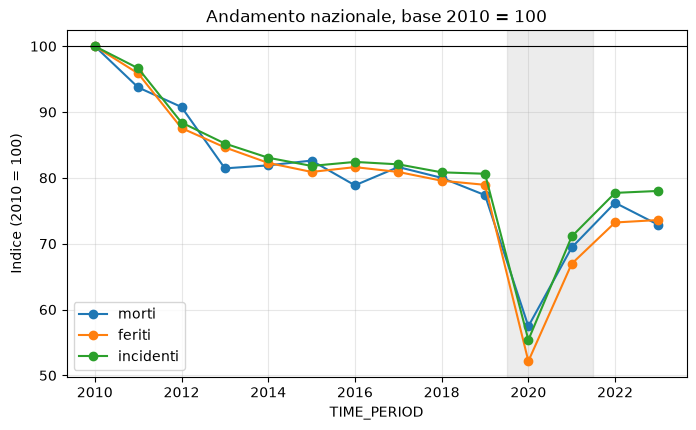

In [4]:
indice = naz / naz.loc[2010] * 100

indice.plot(figsize=(8, 4.5), marker="o")
plt.axvspan(2019.5, 2021.5, alpha=0.15, color="gray")
plt.axhline(100, color="k", lw=0.8)
plt.ylabel("Indice (2010 = 100)")
plt.title("Andamento nazionale, base 2010 = 100")
plt.grid(alpha=0.3)
plt.show()

Raggruppo e classifico per vedre i comuni con maggior numero di incidenti, feriti e morti

In [5]:
tot = df.groupby("REF_AREA").agg(
    Comune=("Comune", "first"),
    morti=("morti", "sum"),
    feriti=("feriti", "sum"),
    incidenti=("incidenti", "sum"),
    pop=("Popolazione residente", "first"),
    densita=("densita", "first"),
).reset_index()

tot["vittime"] = tot["morti"] + tot["feriti"]

print(tot.shape)
tot.nlargest(10, "vittime")

(7388, 8)


,REF_AREA,Comune,morti,feriti,incidenti,pop,densita,vittime
4608,58091,Roma,2066,245835,189514,2747290,2132.678667,247901
1748,15146,Milano,638,161379,123692,1365698,7513.888087,162017
1253,10025,Genova,340,70285,57278,564080,2343.944132,70625
266,1272,Torino,390,63639,43037,853196,6563.106736,64029
4119,48017,Firenze,202,42814,35473,361705,3535.462140,43016
4993,63049,Napoli,433,42447,31729,909013,7623.127685,42880
6479,82053,Palermo,336,39477,29288,628693,3913.004240,39813
3748,37006,Bologna,264,35596,27455,390151,2769.855193,35860
5766,72006,Bari,158,34405,23170,315831,2686.622393,34563
6716,87015,Catania,246,23771,17625,298054,1630.331805,24017


Verifico se ha senso mettere in correlazione gli gli incidenti con la popolazione

In [6]:
tot["vittime_100k_anno"] = tot["vittime"] / 14 / tot["pop"] * 100_000
tot["morti_100k_anno"] = tot["morti"] / 14 / tot["pop"] * 100_000


tot.nlargest(10, "vittime_100k_anno")[["Comune", "pop", "vittime", "morti_100k_anno"]]

,Comune,pop,vittime,morti_100k_anno
1029,Bard,102,46,210.084034
524,Castelmagno,51,19,700.280112
4531,Camerata Nuova,402,145,35.536603
646,Priero,486,173,14.697237
6995,Dorio,339,116,42.140750
385,Villarboit,371,124,211.782826
5394,Rocca Pia,169,56,169.061708
479,Argentera,77,25,0.000000
331,Collobiano,72,23,0.000000
1480,Brienno,311,99,137.804318


Lo faccio anche verificando la gravità (morti) se mi sposta qualcosa

In [7]:
tot["vittime_100k_anno"] = tot["vittime"] / 14 / tot["pop"] * 100_000
tot["morti_100k_anno"] = tot["morti"] / 14 / tot["pop"] * 100_000


tot.nlargest(10, "morti_100k_anno")[["Comune", "pop", "vittime", "vittime_100k_anno"]]

,Comune,pop,vittime,vittime_100k_anno
524,Castelmagno,51,19,2661.064426
504,Briga Alta,40,6,1071.428571
161,Noasca,99,17,1226.551227
385,Villarboit,371,124,2387.370042
363,Rassa,68,2,210.084034
1029,Bard,102,46,3221.288515
675,Sambuco,82,19,1655.052265
5394,Rocca Pia,169,56,2366.863905
612,Montezemolo,222,49,1576.576577
5592,San Giovanni Lipioni,136,15,787.815126


Metto su uno scatter per vedere come si distribuisce il dato

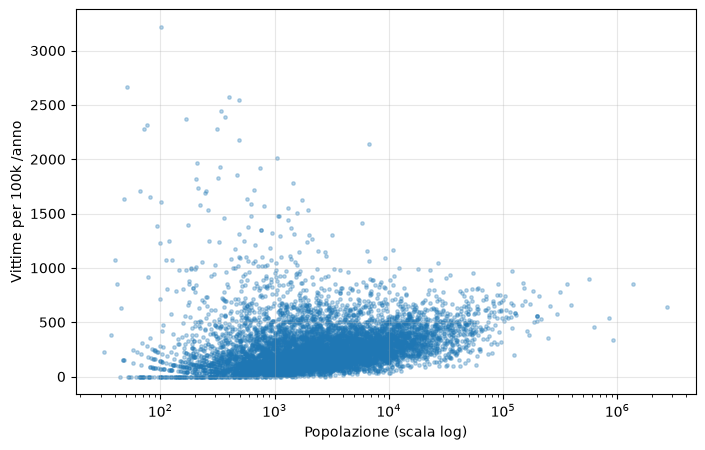

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(tot["pop"], tot["vittime_100k_anno"], s=6, alpha=0.3)
plt.xscale("log")

plt.xlabel("Popolazione (scala log)")
plt.ylabel("Vittime per 100k /anno")
plt.grid(alpha=0.3)
plt.show()

Outlier e instabilità dei tassi nei comuni piccoli

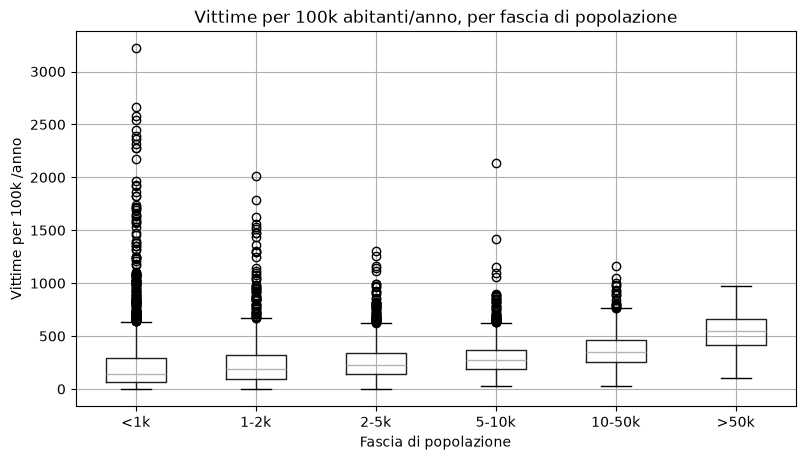

In [9]:
import pandas as pd

tot["fascia_pop"] = pd.cut(
    tot["pop"],
    bins=[0, 1_000, 2_000, 5_000, 10_000, 50_000, float("inf")],
    labels=["<1k", "1-2k", "2-5k", "5-10k", "10-50k", ">50k"],
    right=False,
)

tot.boxplot(column="vittime_100k_anno", by="fascia_pop", figsize=(9, 5))
plt.suptitle("")
plt.title("Vittime per 100k abitanti/anno, per fascia di popolazione")
plt.xlabel("Fascia di popolazione")
plt.ylabel("Vittime per 100k /anno")
plt.show()

In [10]:
q1, q3 = tot["vittime_100k_anno"].quantile([0.25, 0.75])
soglia_alta = q3 + 1.5 * (q3 - q1)

tot["outlier"] = tot["vittime_100k_anno"] > soglia_alta
print(f"Outlier: {tot['outlier'].sum()} su {len(tot)} comuni")

# dove si concentrano?
print(tot.groupby("fascia_pop", observed=True)["outlier"].agg(["sum", "mean"]).round(3))

# i casi più estremi, con i numeri assoluti
tot["vittime_anno"] = tot["vittime"] / 14
(tot.nlargest(10, "vittime_100k_anno")
    [["Comune", "pop", "vittime_anno", "vittime_100k_anno"]])

Outlier: 278 su 7388 comuni
            sum   mean
fascia_pop            
<1k         123  0.066
1-2k         53  0.038
2-5k         33  0.018
5-10k        25  0.023
10-50k       24  0.023
>50k         20  0.152


,Comune,pop,vittime_anno,vittime_100k_anno
1029,Bard,102,3.285714,3221.288515
524,Castelmagno,51,1.357143,2661.064426
4531,Camerata Nuova,402,10.357143,2576.403696
646,Priero,486,12.357143,2542.621987
6995,Dorio,339,8.285714,2444.163506
385,Villarboit,371,8.857143,2387.370042
5394,Rocca Pia,169,4.000000,2366.863905
479,Argentera,77,1.785714,2319.109462
331,Collobiano,72,1.642857,2281.746032
1480,Brienno,311,7.071429,2273.771245


In [11]:
big = tot[tot["pop"] >= 5_000].copy()

def flag_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 1.5 * (q3 - q1)

big["outlier_fascia"] = big.groupby("fascia_pop", observed=True)["vittime_100k_anno"].transform(flag_iqr)

print(big.groupby("fascia_pop", observed=True)["outlier_fascia"].agg(["sum", "mean"]).round(3))

(big[big["outlier_fascia"]]
    .nlargest(15, "vittime_100k_anno")
    [["Comune", "pop", "vittime_anno", "vittime_100k_anno"]])

            sum   mean
fascia_pop            
5-10k        52  0.047
10-50k       19  0.018
>50k          0  0.000


,Comune,pop,vittime_anno,vittime_100k_anno
4069,Forte dei Marmi,6666,142.571429,2138.785307
3747,Bentivoglio,5821,82.428571,1416.055170
4108,Barberino di Mugello,10939,127.142857,1162.289580
5946,Porto Cesareo,6486,74.928571,1155.235452
1682,Assago,9323,102.000000,1094.068433
1805,Zibido San Giacomo,6675,70.714286,1059.390048
3234,Jesolo,26994,282.642857,1047.058076
1256,Lavagna,12367,123.785714,1000.935670
4110,Calenzano,17994,177.642857,987.233840
4079,Pietrasanta,22743,222.071429,976.438590


Cosa osservo. Dopo aver valutato gli outlier dentro ciascuna fascia di popolazione, ne restano 71 tra i comuni ≥5k, nessuno sopra i 50k. A differenza dei comuni piccoli, questi hanno volumi di incidenti elevati (70-280 vittime l’anno).
Interpretazione. Si tratta in gran parte di località turistiche, nodi autostradali o logistici e comuni dell’hinterland milanese. Il tasso per residente è alto perché sul territorio si muovono molte più persone dei residenti. Non indica per forza che vi sia un rischio maggiore per chi ci abita.
Decisione. Non li escludo: sono segnale, non errore. Li marco con un flag e li tratto come segmento a parte nell’analisi finale.
Limite. Non ho dati sulle presenze effettive; la lettura “turismo e transito” è un’ipotesi da validare con dati aggiuntivi.

In [12]:
top = big[big["outlier_fascia"]].nlargest(15, "vittime_100k_anno").copy()
top = top.merge(df[["REF_AREA", "Regione"]].drop_duplicates(), on="REF_AREA", how="left")

top["vittime_anno"] = top["vittime"] / 14
top["inc_kmq_anno"] = top["incidenti"] / 14 * top["densita"] / top["pop"]
top["gravita"] = top["morti"] / top["incidenti"] * 1000

top[["Comune", "Regione", "pop", "vittime_anno", "vittime_100k_anno",
     "inc_kmq_anno", "gravita"]].round(1)

,Comune,Regione,pop,vittime_anno,vittime_100k_anno,inc_kmq_anno,gravita
0,Forte dei Marmi,Toscana,6666,142.6,2138.8,11.5,6.7
1,Bentivoglio,Emilia-Romagna,5821,82.4,1416.1,1.0,29.7
2,Barberino di Mugello,Toscana,10939,127.1,1162.3,0.6,25.9
3,Porto Cesareo,Puglia,6486,74.9,1155.2,1.1,25.8
4,Assago,Lombardia,9323,102.0,1094.1,9.1,5.9
5,Zibido San Giacomo,Lombardia,6675,70.7,1059.4,1.8,26.0
6,Jesolo,Veneto,26994,282.6,1047.1,2.0,20.8
7,Lavagna,Liguria,12367,123.8,1000.9,6.9,7.5
8,Calenzano,Toscana,17994,177.6,987.2,1.7,16.8
9,Pietrasanta,Toscana,22743,222.1,976.4,4.1,17.9


In [13]:
serie = (df[df["REF_AREA"].isin(top["REF_AREA"])]
         .pivot(index="TIME_PERIOD", columns="Comune", values="incidenti"))

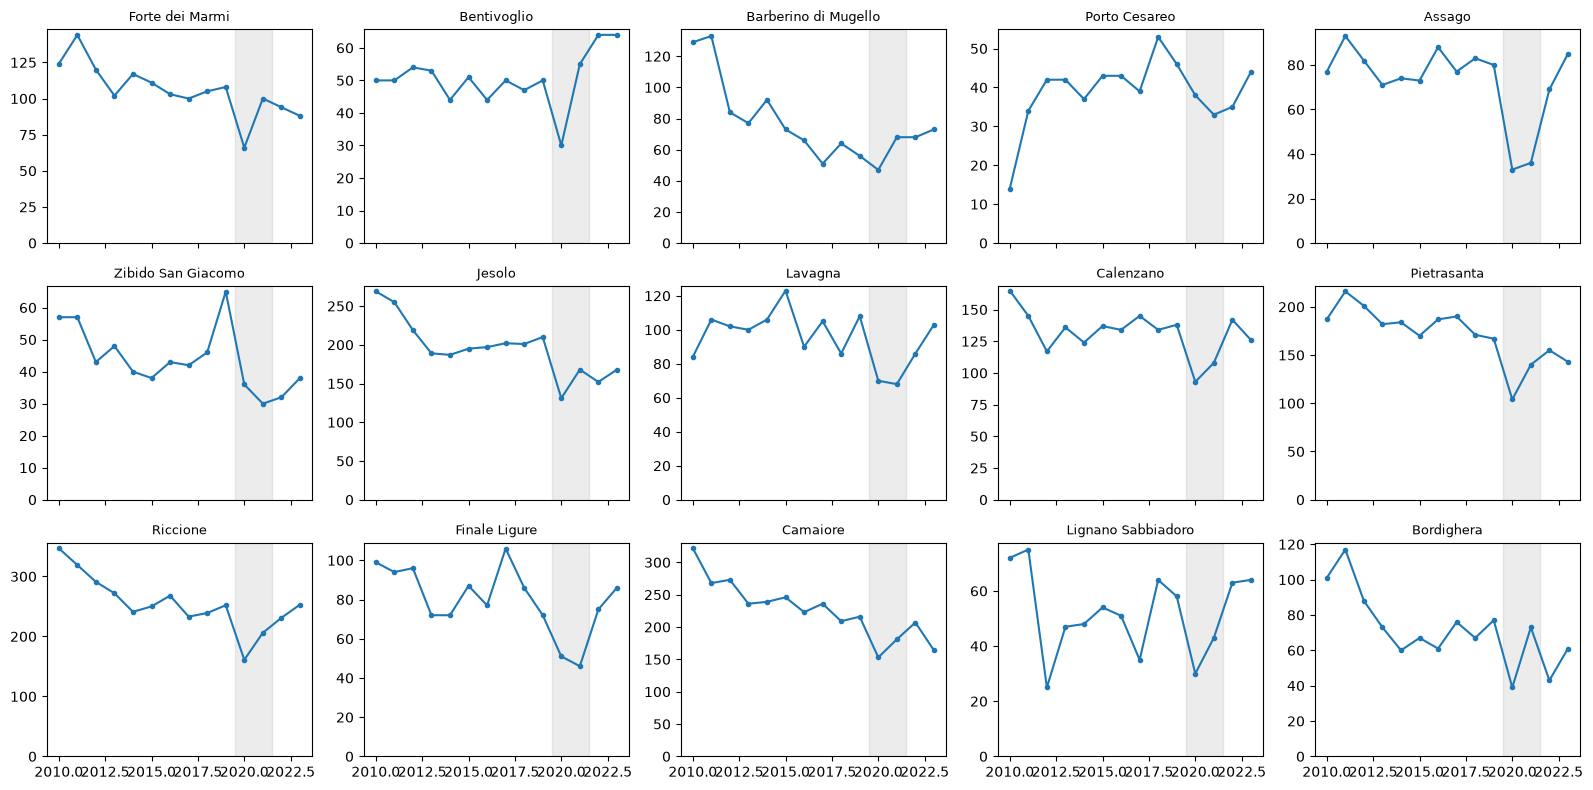

In [14]:
ordine = top["Comune"].tolist()   # già ordinati per tasso
fig, axes = plt.subplots(3, 5, figsize=(16, 8), sharex=True)
for ax, com in zip(axes.flat, ordine):
    ax.plot(serie.index, serie[com], marker="o", ms=3)
    ax.axvspan(2019.5, 2021.5, alpha=0.15, color="gray")
    ax.set_title(com, fontsize=9)
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

In [15]:
naz_inc = naz["incidenti"]

In [16]:
base = serie.loc[2018:2019].mean()
rec  = serie.loc[2022:2023].mean()
trend = (rec / base * 100).round(0)

naz_trend = round(naz_inc.loc[2022:2023].mean() / naz_inc.loc[2018:2019].mean() * 100)
print("Italia 2022-23 vs 2018-19:", naz_trend)

top["trend"] = top["Comune"].map(trend)
top[["Comune", "Regione", "vittime_100k_anno", "inc_kmq_anno", "gravita", "trend"]] \
    .sort_values("trend", ascending=False).round(1)

Italia 2022-23 vs 2018-19: 96


,Comune,Regione,vittime_100k_anno,inc_kmq_anno,gravita,trend
1,Bentivoglio,Emilia-Romagna,1416.1,1.0,29.7,132.0
2,Barberino di Mugello,Toscana,1162.3,0.6,25.9,118.0
13,Lignano Sabbiadoro,Friuli-Venezia Giulia,898.0,3.3,4.1,104.0
11,Finale Ligure,Liguria,924.3,2.2,11.6,102.0
8,Calenzano,Toscana,987.2,1.7,16.8,99.0
10,Riccione,Emilia-Romagna,932.3,14.5,6.2,99.0
7,Lavagna,Liguria,1000.9,6.9,7.5,97.0
4,Assago,Lombardia,1094.1,9.1,5.9,94.0
9,Pietrasanta,Toscana,976.4,4.1,17.9,88.0
12,Camaiore,Toscana,907.7,2.7,15.1,87.0


In [17]:
from scipy.stats import binomtest

base_sum = serie.loc[2018:2019].sum()
rec_sum  = serie.loc[2022:2023].sum()

r  = naz_inc.loc[2022:2023].sum() / naz_inc.loc[2018:2019].sum()   # rapporto nazionale
p0 = r / (1 + r)   # quota attesa di incidenti nel periodo recente, se il comune segue l'Italia

righe = []
for com in top["Comune"]:
    n1, n2 = int(base_sum[com]), int(rec_sum[com])
    p = binomtest(n2, n1 + n2, p0).pvalue
    righe.append({"Comune": com, "inc_2018_19": n1, "inc_2022_23": n2,
                  "trend": round(n2 / n1 / r * 100), "p_value": p})

test = pd.DataFrame(righe)
test.sort_values("p_value").round(4)

,Comune,inc_2018_19,inc_2022_23,trend,p_value
6,Jesolo,411,320,81,0.0044
5,Zibido San Giacomo,111,70,65,0.0058
1,Bentivoglio,97,128,137,0.0197
14,Bordighera,144,104,75,0.0261
2,Barberino di Mugello,120,141,122,0.1216
12,Camaiore,425,371,91,0.1668
3,Porto Cesareo,99,79,83,0.2303
0,Forte dei Marmi,213,182,89,0.2471
9,Pietrasanta,338,298,91,0.2669
13,Lignano Sabbiadoro,122,127,108,0.5686


In [18]:
print(r, type(r))

0.9645056333862163 <class 'numpy.float64'>


In [23]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -----------

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

big["incidenti_100k_anno"] = big["incidenti"] / 14 / big["pop"] * 100_000
big["gravita"] = big["morti"] / big["incidenti"].where(big["incidenti"] > 0) * 1000
big["log_dens"] = np.log10(big["densita"])
big["log_pop"] = np.log10(big["pop"])

feat = ["incidenti_100k_anno", "gravita", "log_dens", "log_pop"]
X = big[feat].dropna()
Xs = StandardScaler().fit_transform(X)

km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xs)
print("Silhouette:", round(silhouette_score(Xs, km.labels_), 3))

big.loc[X.index, "cluster"] = km.labels_
p = big.groupby("cluster").agg(
    comuni=("REF_AREA", "count"), pop_med=("pop", "median"),
    dens_med=("densita", "median"), inc100k=("incidenti_100k_anno", "median"),
    grav=("gravita", "median"), quota_outlier=("outlier_fascia", "mean"),
    top15=("top15", "sum") if "top15" in big else ("outlier_fascia", "sum")).round(2)
print(p)

Silhouette: 0.245
         comuni  pop_med  dens_med  inc100k   grav  quota_outlier  top15
cluster                                                                 
0.0         987   8364.0    204.24   210.36  31.25           0.03     28
1.0         381  35474.0    643.40   387.78  13.92           0.11     41
2.0         166   6576.5    130.46   119.28  79.25           0.00      0
3.0         727  11608.0    929.81   185.55  18.18           0.00      2


In [26]:
print(big[big["REF_AREA"].isin(top["REF_AREA"])].groupby("cluster").size())

cluster
1.0    15
dtype: int64


In [27]:
nomi = {p["inc100k"].idxmax(): "Centri grandi, tasso alto",
        p["grav"].idxmax(): "Piccoli comuni, incidenti rari e letali"}
resto = p.drop(index=list(nomi)).sort_values("dens_med")
nomi[resto.index[0]] = "Comuni medi e radi, più letali"
nomi[resto.index[1]] = "Comuni medi e densi, rischio basso"
big["cluster_nome"] = big["cluster"].map(nomi)
print(big["cluster_nome"].value_counts())

cluster_nome
Comuni medi e radi, più letali             987
Comuni medi e densi, rischio basso         727
Centri grandi, tasso alto                  381
Piccoli comuni, incidenti rari e letali    166
Name: count, dtype: int64


In [29]:
# --- tabella comuni: una riga per comune ---
extra = (df[["REF_AREA", "Regione", "Sigla automobilistica", "Superficie (Kmq)"]]
         .drop_duplicates("REF_AREA"))

comuni = tot.drop(columns=["fascia_pop", "outlier"], errors="ignore")
comuni = comuni.merge(extra, on="REF_AREA", how="left")
comuni = comuni.merge(big[["REF_AREA", "fascia_pop", "outlier_fascia", "cluster_nome"]], on="REF_AREA", how="left")

comuni["analizzabile"] = comuni["pop"] >= 5_000
comuni["outlier_fascia"] = comuni["outlier_fascia"].fillna(False).astype(bool)
comuni["vittime_anno"] = comuni["vittime"] / 14
comuni["gravita"] = comuni["morti"] / comuni["incidenti"].where(comuni["incidenti"] > 0) * 1000
comuni["inc_kmq_anno"] = comuni["incidenti"] / 14 / comuni["Superficie (Kmq)"]

# --- top 15, trend e test ---
t = top[["REF_AREA", "Comune", "trend"]].rename(columns={"trend": "trend_vs_2019"})
t = t.merge(test[["Comune", "trend", "p_value"]].rename(columns={"trend": "trend_vs_italia"}),
            on="Comune", how="left")
comuni = comuni.merge(t.drop(columns="Comune"), on="REF_AREA", how="left")
comuni["top15"] = comuni["REF_AREA"].isin(top["REF_AREA"])

# --- tipologia: classificazione tua, da verificare ---
costieri = ["Forte dei Marmi", "Pietrasanta", "Camaiore", "Jesolo", "Riccione", "Lignano Sabbiadoro",
            "Bordighera", "Finale Ligure", "Lavagna", "Porto Cesareo"]
logistici = ["Barberino di Mugello", "Calenzano", "Bentivoglio"]
milano = ["Assago", "Zibido San Giacomo"]

comuni["tipologia"] = None
comuni.loc[comuni["Comune"].isin(costieri), "tipologia"] = "Turistico-costiero"
comuni.loc[comuni["Comune"].isin(logistici), "tipologia"] = "Nodo autostradale/logistico"
comuni.loc[comuni["Comune"].isin(milano), "tipologia"] = "Hinterland milanese"



In [30]:
print(comuni["cluster_nome"].value_counts(dropna=False))
print(comuni.shape)

cluster_nome
NaN                                        5127
Comuni medi e radi, più letali              987
Comuni medi e densi, rischio basso          727
Centri grandi, tasso alto                   381
Piccoli comuni, incidenti rari e letali     166
Name: count, dtype: int64
(7388, 25)


In [31]:
comuni.to_csv("comuni_dashboard.csv", index=False, encoding="utf-8-sig")

In [32]:
comuni.info()

<class 'pandas.DataFrame'>
RangeIndex: 7388 entries, 0 to 7387
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   REF_AREA               7388 non-null   int64   
 1   Comune                 7388 non-null   str     
 2   morti                  7388 non-null   int64   
 3   feriti                 7388 non-null   int64   
 4   incidenti              7388 non-null   int64   
 5   pop                    7388 non-null   int64   
 6   densita                7388 non-null   float64 
 7   vittime                7388 non-null   int64   
 8   vittime_100k_anno      7388 non-null   float64 
 9   morti_100k_anno        7388 non-null   float64 
 10  vittime_anno           7388 non-null   float64 
 11  Regione                7388 non-null   str     
 12  Sigla automobilistica  7296 non-null   str     
 13  Superficie (Kmq)       7388 non-null   float64 
 14  fascia_pop             2261 non-null   category
 15